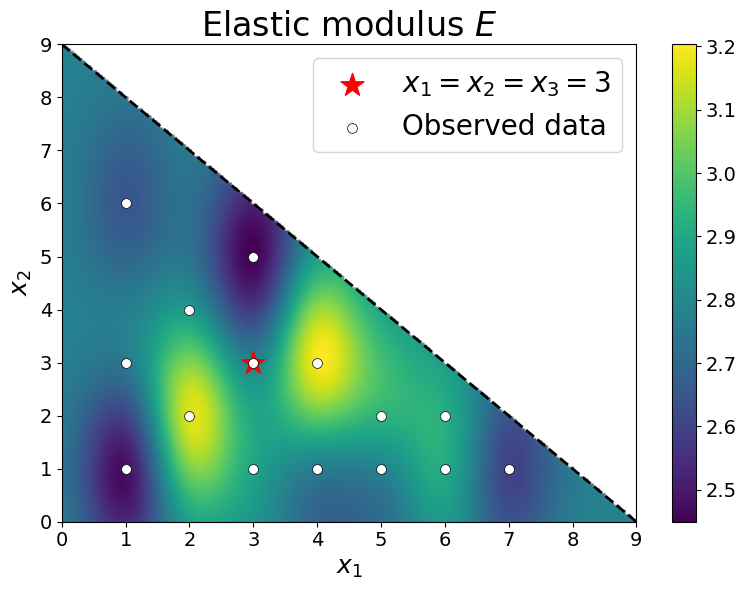

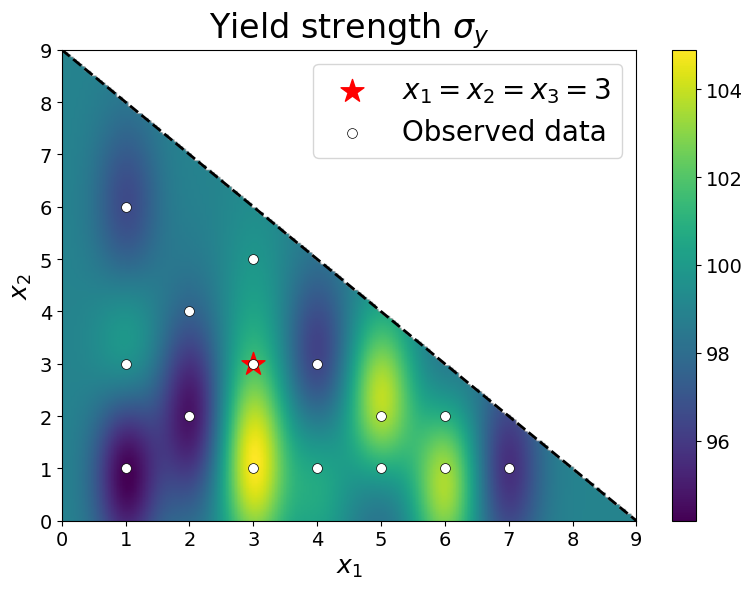

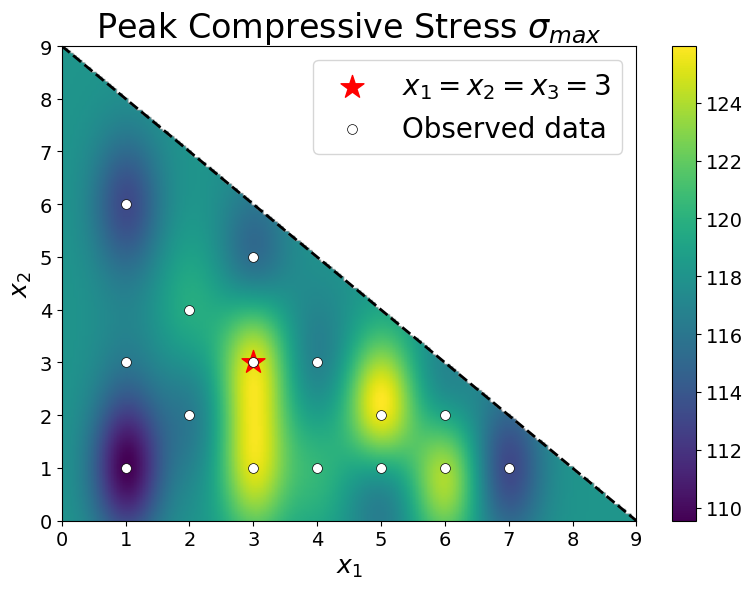

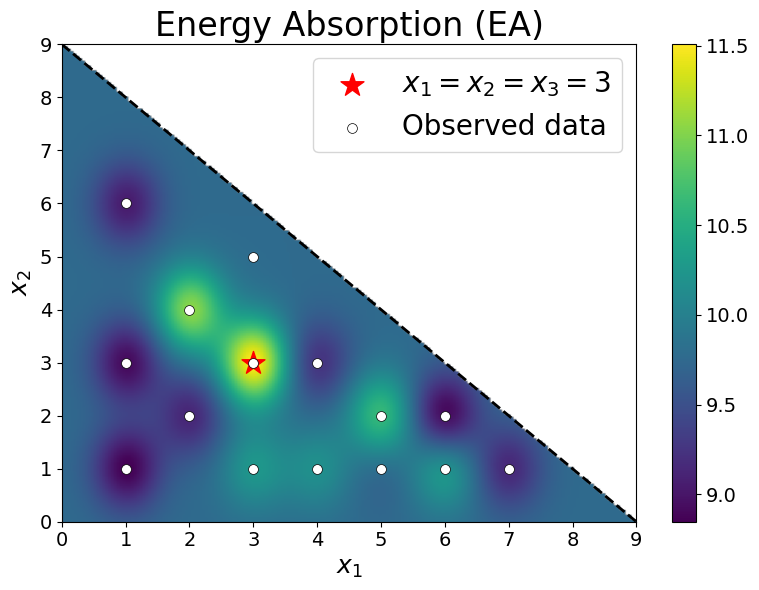

In [5]:
import os
import torch
import numpy as np
import matplotlib.pyplot as plt

from botorch.models import SingleTaskGP
from botorch.fit import fit_gpytorch_mll
from gpytorch.mlls import ExactMarginalLogLikelihood
from botorch.models.transforms import Normalize, Standardize


# ==========================================================
# 1. Data
# ==========================================================

# Data
X = torch.tensor([
    [3.0, 3.0, 3.0],
    [5.0, 2.0, 2.0],
    [3.0, 1.0, 5.0],
    [6.0, 1.0, 2.0],
    [4.0, 1.0, 4.0],
    [2.0, 4.0, 3.0],
    [5.0, 1.0, 3.0],
    [6.0, 2.0, 1.0],
    [3.0, 5.0, 1.0],
    [2.0, 2.0, 5.0],
    [4.0, 3.0, 2.0],
    [1.0, 3.0, 5.0],
    [1.0, 6.0, 2.0],
    [7.0, 1.0, 1.0],
    [1.0, 1.0, 7.0],
], dtype=torch.double)

Y_total = torch.tensor([[[2.79],[2.94],[2.89],[2.91],[2.77],[2.85],[2.79],[2.92],[2.45],[3.17],[3.20],[2.76],[2.65],[2.60],[2.48]],
                       [[101.66],[103.64],[104.92],[103.40],[100.49],[97.55],[100.67],[100.81],[99.80],[94.71],[96.43],[99.48],[96.60],[95.64],[94.19]],
                       [[125.26],[125.68],[125.44],[123.69],[120.43],[119.69],[119.42],[119.22],[115.40],[116.29],[116.85],[116.09],[113.21],[113.15],[109.49]],
                       [[11.52],[10.62],[10.26],[10.17],[10.18],[11.05],[9.84],[8.94],[9.79],[9.13],[9.26],[8.91],[9.04],[9.15],[8.84]],
], dtype=torch.double)



Labels = [
    'Elastic modulus $E$ ',
    'Yield strength $\sigma_y$',
    'Peak Compressive Stress $\sigma_{max}$',
    'Energy Absorption (EA)'
]

save_labels = [
    'Mean_Elastic_modulus',
    'Mean_Yield_strength',
    'Mean_Peak_Compressive_Stress',
    'Mean_Energy_Absorption'
]

for k in range(4):
    # ==========================================================
    # 2. Dimensionality reduction
    # Since x3 = 9 - x1 - x2,
    # only x1 and x2 are kept as GP inputs
    # ==========================================================
    train_X = X[:, :2]
    train_Y = Y_total[k]

    # ==========================================================
    # 3. Build GP (BoTorch)
    # ==========================================================
    model = SingleTaskGP(
        train_X,
        train_Y,
        input_transform=Normalize(d=2),
        outcome_transform=Standardize(m=1),
    )

    mll = ExactMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)

    model.eval()

    # ==========================================================
    # 4. Build 2D grid
    # Feasible region:
    # x1 >= 0
    # x2 >= 0
    # x1 + x2 <= 9
    # ==========================================================
    grid_size = 200

    x1 = np.linspace(0, 9, grid_size)
    x2 = np.linspace(0, 9, grid_size)

    X1, X2 = np.meshgrid(x1, x2)

    mu = np.full_like(X1, np.nan)

    # ==========================================================
    # 5. GP posterior mean
    # ==========================================================
    for i in range(grid_size):
        for j in range(grid_size):

            a = X1[i, j]
            b = X2[i, j]
            c = 9 - a - b

            # Ensure the constraint holds
            if c >= 0:

                x = torch.tensor(
                    [[a, b]],
                    dtype=torch.double
                )

                posterior = model.posterior(x)

                mean = posterior.mean.item()

                mu[i, j] = mean

    # ==========================================================
    # 6. Plot 2D heatmap
    # ==========================================================
    plt.figure(figsize=(8, 6))

    im = plt.imshow(
        mu,
        origin='lower',
        extent=[0, 9, 0, 9],
        aspect='auto',
        cmap='viridis',
    )

    cbar = plt.colorbar(im)
    cbar.ax.tick_params(labelsize=14)

    # Draw the constraint boundary (triangular region)
    plt.plot([0, 9], [9, 0], 'k--', linewidth=2)

    # Mark (3, 3, 3)
    plt.scatter(
        [3],
        [3],
        s=300,
        marker='*',
        label=r'$x_1=x_2=x_3=3$',
        color='red',
    )

    # Training points
    plt.scatter(
        train_X[:, 0].numpy(),
        train_X[:, 1].numpy(),
        s=50,
        label='Observed data',
        color = 'white',
        edgecolors='black',   
        linewidth=0.5 

    )

    plt.xlabel(r'$x_1$', fontsize=18,)
    plt.ylabel(r'$x_2$', fontsize=18,)

    plt.title(rf'{Labels[k]}', fontsize=24,)

    plt.xticks(np.arange(0, 10, 1), fontsize=14)   
    plt.yticks(np.arange(0, 10, 1), fontsize=14)   

    plt.legend(fontsize=20)
    plt.tight_layout()
    
    os.makedirs("figures/individual objective analysis", exist_ok=True)
    save_name = save_labels[k]
    filepath = os.path.join("figures/individual objective analysis", f"{save_name}.pdf")
    plt.savefig(filepath)

    plt.show()

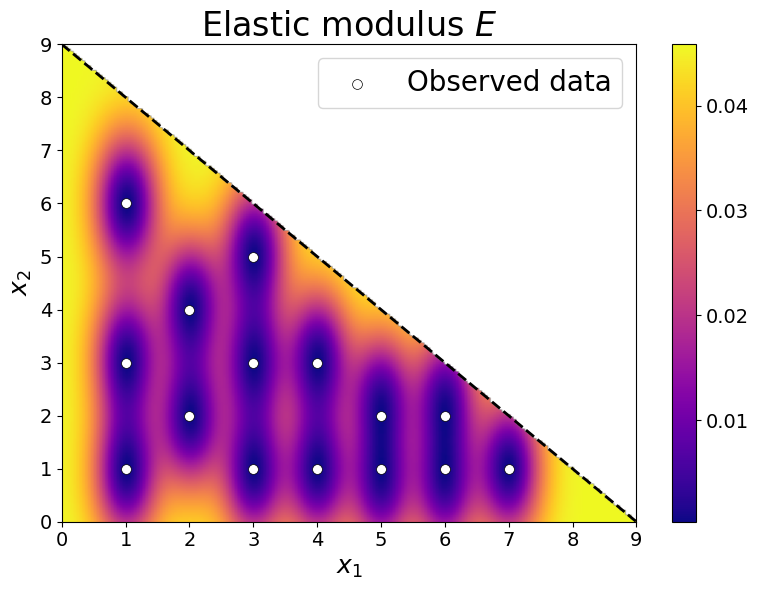

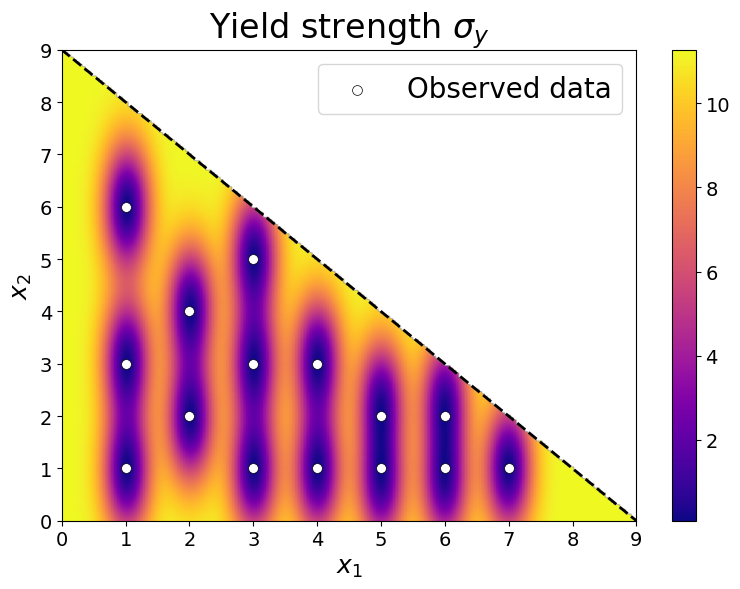

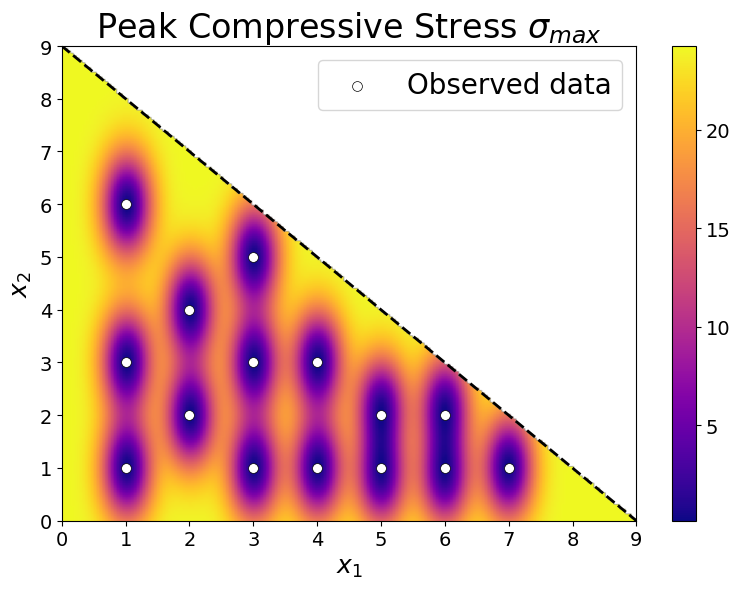

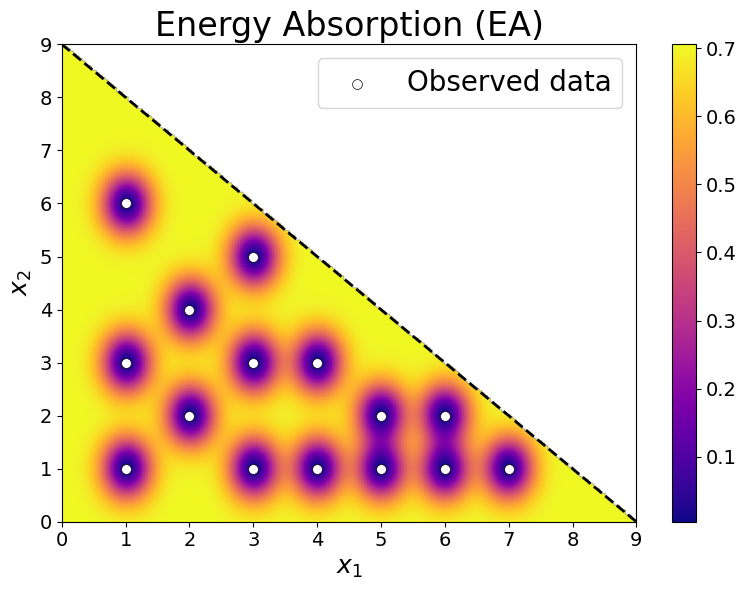

In [6]:
Labels = [
    'Elastic modulus $E$ ',
    'Yield strength $\sigma_y$',
    'Peak Compressive Stress $\sigma_{max}$',
    'Energy Absorption (EA)'
]

save_labels = [
    'Var_Elastic_modulus',
    'Var_Yield_strength',
    'Var_Peak_Compressive_Stress',
    'Var_Energy_Absorption'
]

for k in range(4):
    # ==========================================================
    # 2. Dimensionality reduction
    # Since x3 = 9 - x1 - x2,
    # only x1 and x2 are kept as GP inputs
    # ==========================================================
    train_X = X[:, :2]
    train_Y = Y_total[k]

    # ==========================================================
    # 3. Build GP (BoTorch)
    # ==========================================================
    model = SingleTaskGP(
        train_X,
        train_Y,
        input_transform=Normalize(d=2),
        outcome_transform=Standardize(m=1),
    )

    mll = ExactMarginalLogLikelihood(model.likelihood, model)
    fit_gpytorch_mll(mll)

    model.eval()

    # ==========================================================
    # 4. Build 2D grid
    # Feasible region:
    # x1 >= 0
    # x2 >= 0
    # x1 + x2 <= 9
    # ==========================================================
    grid_size = 200

    x1 = np.linspace(0, 9, grid_size)
    x2 = np.linspace(0, 9, grid_size)

    X1, X2 = np.meshgrid(x1, x2)

    variance = np.full_like(X1, np.nan)

    # ==========================================================
    # 5. GP posterior variance
    # ==========================================================
    for i in range(grid_size):
        for j in range(grid_size):

            a = X1[i, j]
            b = X2[i, j]
            c = 9 - a - b

            if c >= 0:

                x = torch.tensor(
                    [[a, b]],
                    dtype=torch.double
                )

                posterior = model.posterior(x)

                var = posterior.variance.item()

                variance[i, j] = var

    # ==========================================================
    # 6. Plot 2D heatmap
    # ==========================================================
    plt.figure(figsize=(8, 6))

    im = plt.imshow(
        variance,
        origin='lower',
        extent=[0, 9, 0, 9],
        aspect='auto',
        cmap='plasma',
    )

    cbar = plt.colorbar(im)
    cbar.ax.tick_params(labelsize=14)

    plt.plot([0, 9], [9, 0], 'k--', linewidth=2)

    plt.scatter(
        train_X[:, 0].numpy(),
        train_X[:, 1].numpy(),
        s=50,
        label='Observed data',
        color = 'white',
        edgecolors='black',   
        linewidth=0.5  
    )

    plt.xlabel(r'$x_1$', fontsize=18,)
    plt.ylabel(r'$x_2$', fontsize=18,)

    plt.title(rf'{Labels[k]}', fontsize=24,)

    plt.xticks(np.arange(0, 10, 1), fontsize=14)   
    plt.yticks(np.arange(0, 10, 1), fontsize=14)   

    plt.legend(fontsize=20)
    plt.tight_layout()
    
    os.makedirs("figures/individual objective analysis", exist_ok=True)
    save_name = save_labels[k]
    filepath = os.path.join("figures/individual objective analysis", f"{save_name}.svg")
    plt.savefig(filepath)

    plt.show()

# 1. Weighting method

$$
\tilde{f}_i=
\begin{cases}
1-\dfrac{f_i-f_i^{\min}}
        {f_i^{\max}-f_i^{\min}},
& \text{if } f_i \text{ is minimized}, \\[8pt]
\dfrac{f_i-f_i^{\min}}
      {f_i^{\max}-f_i^{\min}},
& \text{if } f_i \text{ is maximized}.
\end{cases}
$$

Composite index: $F = w_1 \tilde{f}_1 + w_2 \tilde{f}_2 + w_3 \tilde{f}_3 + w_4 \tilde{f}_4$ , where ($\sum_{i=1}^4 w_i = 1$)

In [7]:
def normalize_objectives(Y_total):

    Y = torch.cat([
        Y_total[0],
        Y_total[1],
        Y_total[2],
        Y_total[3]
    ], dim=1)

    Y_min = Y.min(dim=0).values
    Y_max = Y.max(dim=0).values

    # Elastic Modulus: the smaller, the better

    F1 = 1 - (Y[:,0]-Y_min[0])/(Y_max[0]-Y_min[0])

    # The others: the larger, the better

    F2 = (Y[:,1]-Y_min[1])/(Y_max[1]-Y_min[1])

    F3 = (Y[:,2]-Y_min[2])/(Y_max[2]-Y_min[2])

    F4 = (Y[:,3]-Y_min[3])/(Y_max[3]-Y_min[3])

    return F1,F2,F3,F4

def mean_draw_gp_heatmap(X, train_Y, title, file_path, file_name):

    train_X = X[:, :2]

    model = SingleTaskGP(
        train_X,
        train_Y,
        input_transform=Normalize(d=2),
        outcome_transform=Standardize(m=1),
    )

    mll = ExactMarginalLogLikelihood(
        model.likelihood,
        model
    )

    fit_gpytorch_mll(mll)

    model.eval()

    grid_size = 200

    x1 = np.linspace(0,9,grid_size)
    x2 = np.linspace(0,9,grid_size)

    X1,X2 = np.meshgrid(x1,x2)

    mu = np.full_like(X1,np.nan)

    for i in range(grid_size):
        for j in range(grid_size):

            a = X1[i,j]
            b = X2[i,j]

            c = 9-a-b

            if c >= 0:

                x = torch.tensor(
                    [[a,b]],
                    dtype=torch.double
                )

                posterior = model.posterior(x)

                mu[i,j] = posterior.mean.item()

    plt.figure(figsize=(8,6))

    im = plt.imshow(
        mu,
        origin='lower',
        extent=[0,9,0,9],
        aspect='auto',
        cmap='viridis',
    )

    cbar = plt.colorbar(im)
    cbar.ax.tick_params(labelsize=14)

    plt.plot(
        [0,9],
        [9,0],
        'k--',
        linewidth=2
    )

    plt.scatter(
        [3],
        [3],
        s=300,
        marker='*',
        color='red',
        label=r'$x_1=x_2=x_3=3$'
    )

    plt.scatter(
        train_X[:,0],
        train_X[:,1],
        s=50,
        color='white',
        edgecolors='black',
        linewidth=0.5,
        label='Observed data'
    )

    plt.xlabel(r'$x_1$', fontsize=18,)
    plt.ylabel(r'$x_2$', fontsize=18,)

    plt.title(title, fontsize=24,)

    plt.xticks(np.arange(0, 10, 1), fontsize=14)   
    plt.yticks(np.arange(0, 10, 1), fontsize=14)   

    plt.legend(fontsize=20)
    plt.tight_layout()
    
    os.makedirs(file_path, exist_ok=True)
    filepath = os.path.join(file_path, f"{file_name}.svg")
    plt.savefig(filepath)

    plt.show()

def variance_draw_gp_heatmap(X, train_Y, title, file_path, file_name):

    train_X = X[:, :2]

    model = SingleTaskGP(
        train_X,
        train_Y,
        input_transform=Normalize(d=2),
        outcome_transform=Standardize(m=1),
    )

    mll = ExactMarginalLogLikelihood(
        model.likelihood,
        model
    )

    fit_gpytorch_mll(mll)

    model.eval()

    grid_size = 200

    x1 = np.linspace(0,9,grid_size)
    x2 = np.linspace(0,9,grid_size)

    X1,X2 = np.meshgrid(x1,x2)

    variance = np.full_like(X1,np.nan)

    for i in range(grid_size):
        for j in range(grid_size):

            a = X1[i,j]
            b = X2[i,j]

            c = 9-a-b

            if c >= 0:

                x = torch.tensor(
                    [[a,b]],
                    dtype=torch.double
                )

                posterior = model.posterior(x)

                variance[i,j] = posterior.variance.item()

    plt.figure(figsize=(8,6))

    im = plt.imshow(
        variance,
        origin='lower',
        extent=[0,9,0,9],
        aspect='auto',
        cmap='plasma',
    )

    cbar = plt.colorbar(im)
    cbar.ax.tick_params(labelsize=14)

    plt.plot(
        [0,9],
        [9,0],
        'k--',
        linewidth=2
    )

    plt.scatter(
        train_X[:,0],
        train_X[:,1],
        s=50,
        color='white',
        edgecolors='black',
        linewidth=0.5,
        label='Observed data'
    )

    plt.xlabel(r'$x_1$', fontsize=18,)
    plt.ylabel(r'$x_2$', fontsize=18,)

    plt.title(title, fontsize=24,)

    plt.xticks(np.arange(0, 10, 1), fontsize=14)   
    plt.yticks(np.arange(0, 10, 1), fontsize=14)   

    plt.legend(fontsize=20)
    plt.tight_layout()
    
    os.makedirs(file_path, exist_ok=True)
    filepath = os.path.join(file_path, f"{file_name}.svg")
    plt.savefig(filepath)

    plt.show()

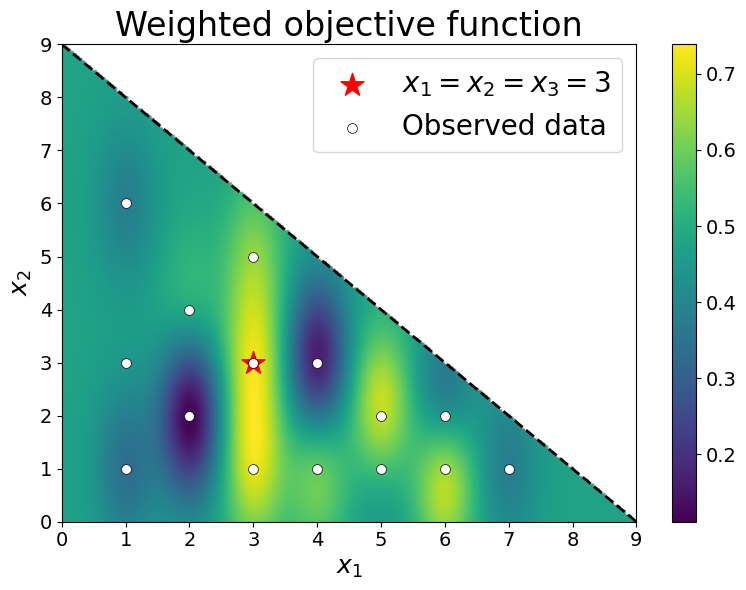

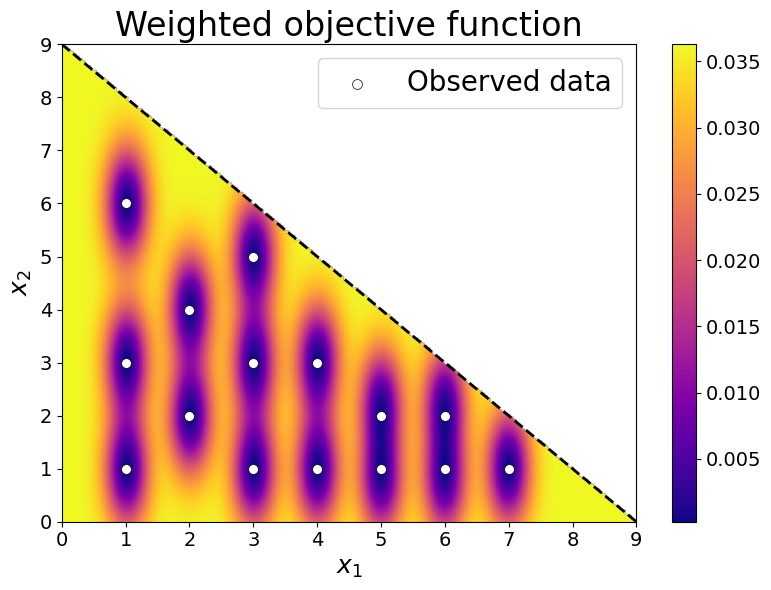

In [8]:

F1,F2,F3,F4 = normalize_objectives(Y_total)

w = torch.tensor([0.35, 0.35, 0.15, 0.15])
F_weight = w[0]*F1 + w[1]*F2 + w[2]*F3 + w[3]*F4

X = train_X

mean_draw_gp_heatmap(
    X,
    F_weight.reshape(-1,1),
    'Weighted objective function',
    "figures/weighted objective function",
    "Mean_weight_method"
)

variance_draw_gp_heatmap(
    X,
    F_weight.reshape(-1,1),
    'Weighted objective function',
    "figures/weighted objective function",
    "Var_weight_method"
)


# 2. Geometric mean method

$$
F = (\tilde{f}_1 \cdot \tilde{f}_2 \cdot \tilde{f}_3 \cdot \tilde{f}_4)^{\frac{1}{4}}
$$

If any single term is particularly poor, the overall score will be low, emphasizing that every term must be excellent.

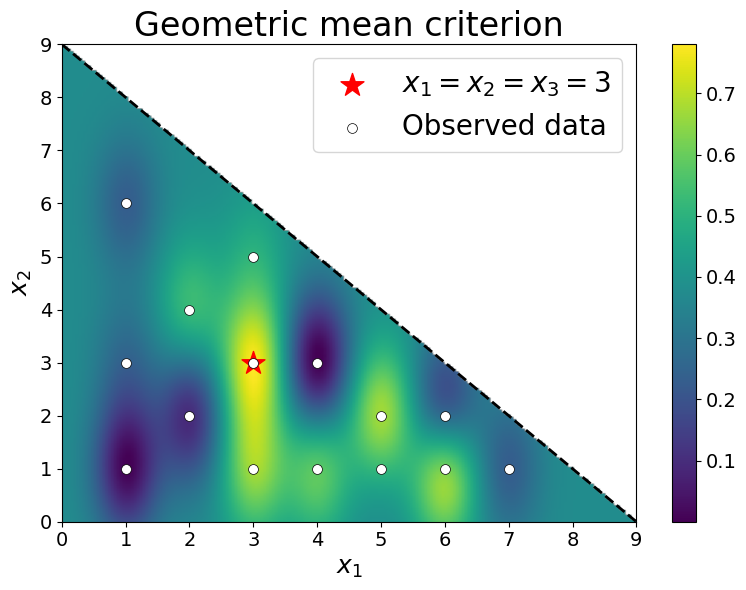

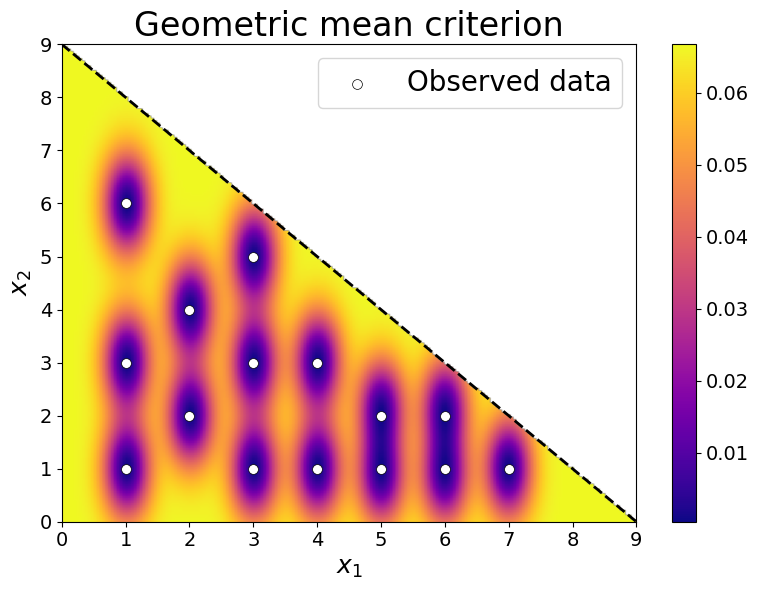

In [9]:
F1,F2,F3,F4 = normalize_objectives(Y_total)

F_geo = (
    F1*F2*F3*F4
)**0.25

mean_draw_gp_heatmap(
    X,
    F_geo.reshape(-1,1),
    'Geometric mean criterion',
    "figures/geometric mean criterion",
    "Mean_geometric_method",    
)

variance_draw_gp_heatmap(
    X,
    F_geo.reshape(-1,1),
    'Geometric mean criterion',
    "figures/geometric mean criterion",
    "Var_geometric_method",  
)

# 3. Distance to the ideal point

Ideal point: (1, 1, 1, 1)

Distance: $d = \sqrt{(1-\tilde{f}_1)^2 + (1-\tilde{f}_2)^2 + (1-\tilde{f}_3)^2 + (1-\tilde{f}_4)^2}$, the smaller, the better

Therefore: $F = -d$

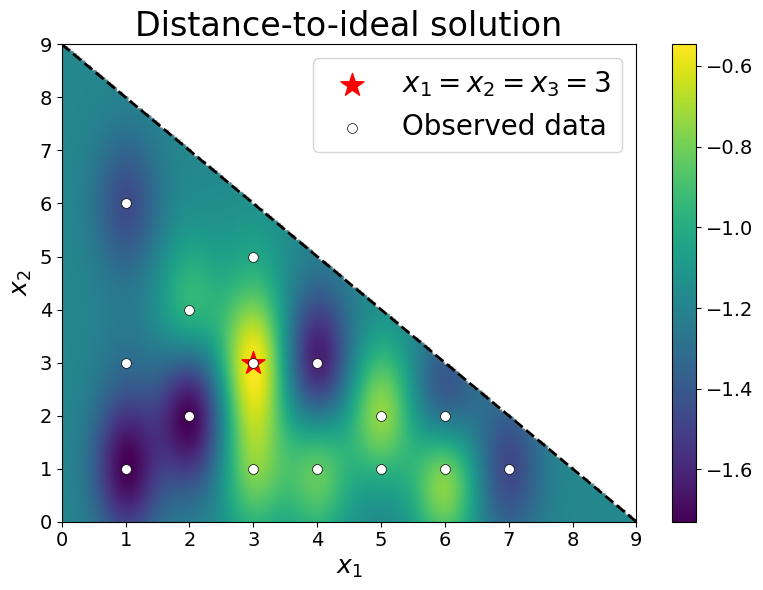

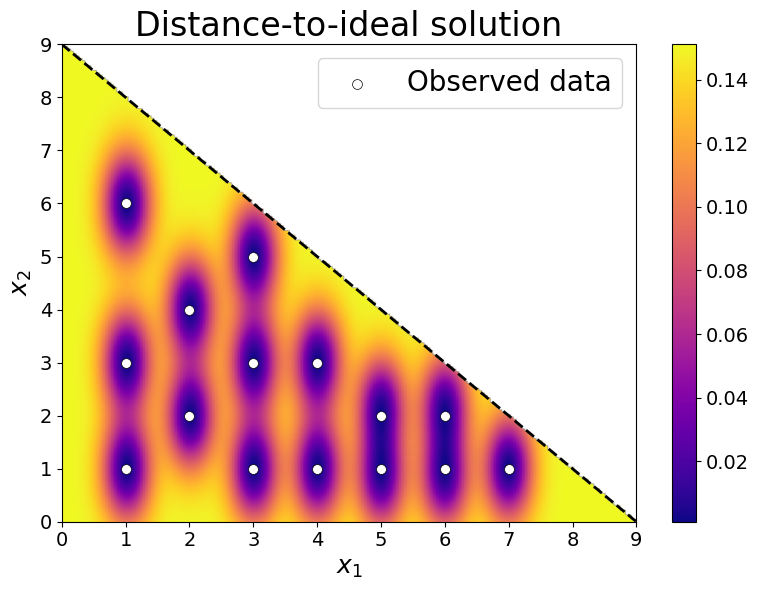

In [10]:
F1,F2,F3,F4 = normalize_objectives(Y_total)

dist = torch.sqrt(
    (1-F1)**2 +
    (1-F2)**2 +
    (1-F3)**2 +
    (1-F4)**2
)

F_dist = -dist

mean_draw_gp_heatmap(
    X,
    F_dist.reshape(-1,1),
    'Distance-to-ideal solution',
    "figures/distance-to-ideal solution",
    "Mean_distance_method",     
)

variance_draw_gp_heatmap(
    X,
    F_dist.reshape(-1,1),
    'Distance-to-ideal solution',
    "figures/distance-to-ideal solution",
    "Var_distance_method",     
)
